# Fitting the Matterhorn

Personal project (2021). A photo of a Matterhorn-shaped wall decoration is turned into a 1D skyline profile, which is then fitted with several analytic models (Gaussian, Moffat, skewed variants, high-degree polynomials, and Moffat + polynomial with astropy). A hand-drawn sun is added for the final figure.

Inputs: `Matterhorn.jpeg` (my photo) and `SUN.png` (a sun drawn with Python).

## 1. Load images

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import median_filter
from lmfit import Model

In [ ]:
img = Image.open('Matterhorn.jpeg')
sun = Image.open('SUN.png')
sun = np.array(sun)

In [5]:
good_sun = np.array(sun[:,::,0])
good_sun.shape

(1189, 1527)

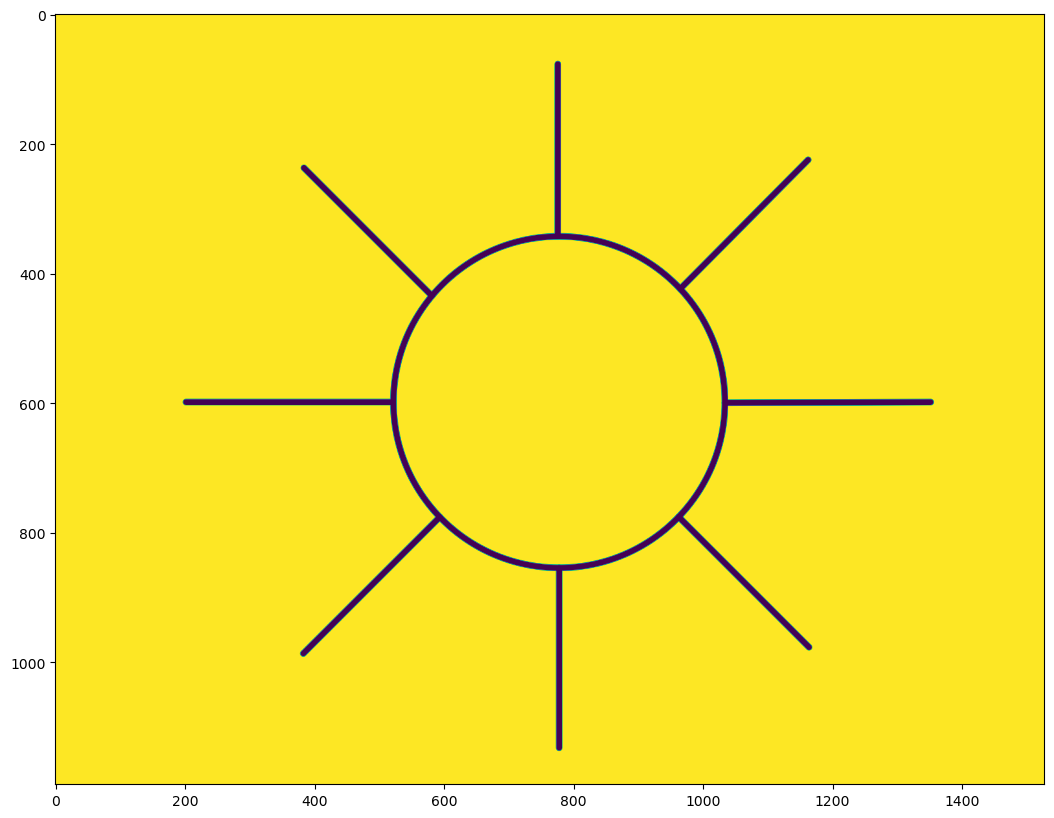

In [8]:
plt.figure(figsize=(15,10))
plt.imshow(good_sun)

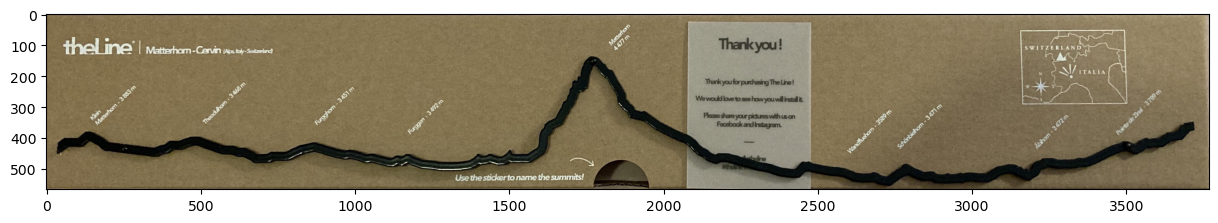

In [9]:
plt.figure(figsize=(15,30))
plt.imshow(img)

In [10]:
img = np.array(img)
img[:,::,0].shape

(567, 3768)

In [11]:
img.shape

(567, 3768, 3)

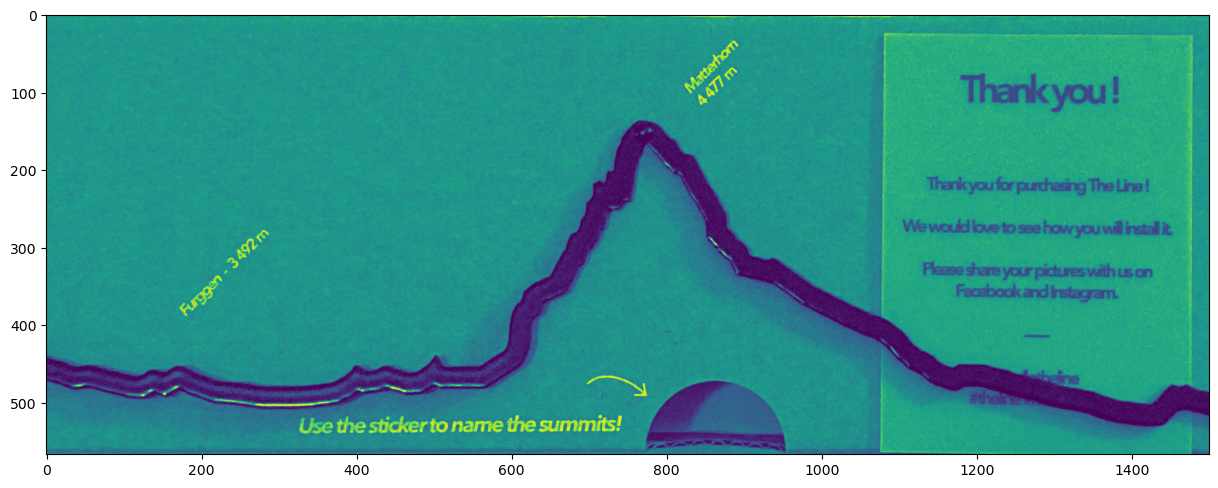

In [13]:
plt.figure(figsize=(15,30))
plt.imshow(img[:,::,0][:,1000:2500])

In [ ]:
img_cut = img[:,::,0][:,1000:2500]

## 2. Extract the skyline
For each pixel column, take the row of the darkest pixel, then smooth with a median filter and centre the profile on the summit.

In [15]:
Positions = np.empty(len(img_cut[0]))
for i in range(len(img_cut[0])):
    Positions[i] = int(np.max( (np.where( img_cut[:,i] == np.min(img_cut[:,i])  )[0]) ))

In [16]:
x = np.arange(len(Positions))

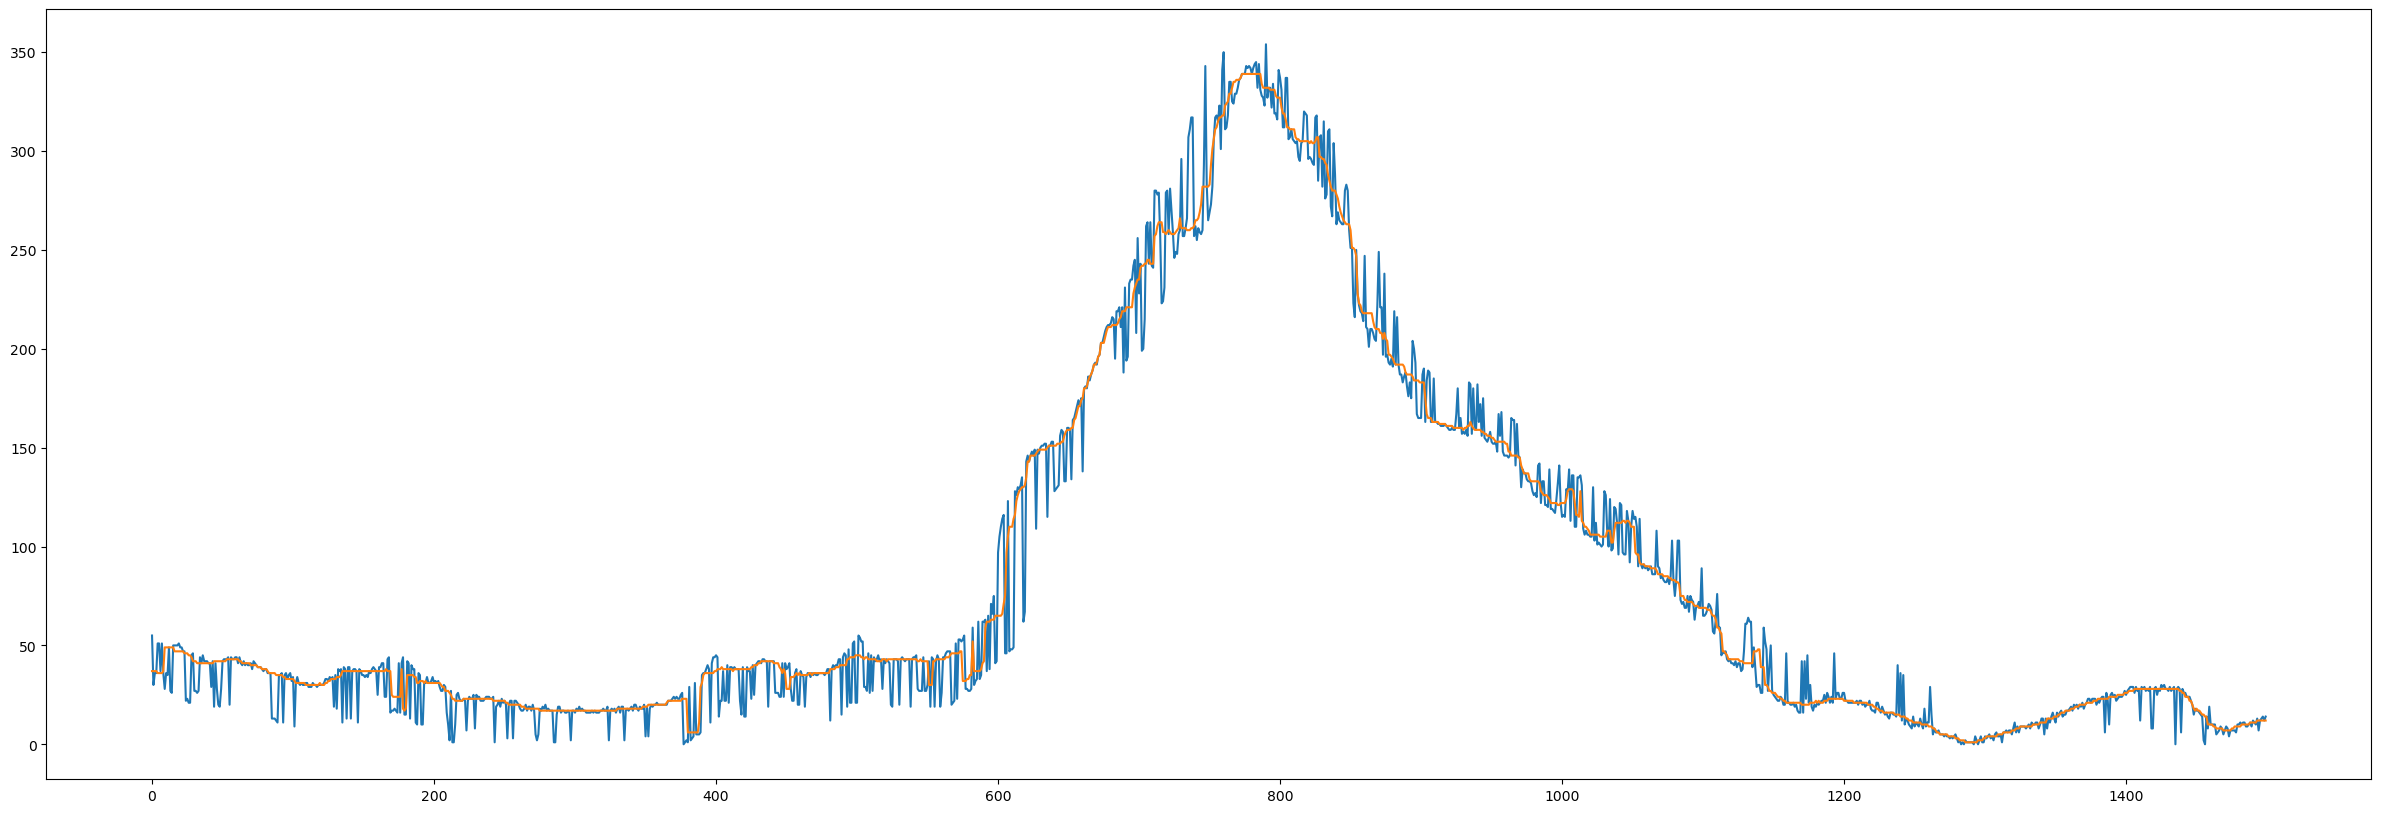

In [17]:
plt.figure(figsize=(30,10))
plt.plot(x,np.abs(Positions-500))
plt.plot(x,median_filter(np.abs(Positions-500),20))

In [18]:
Matti = median_filter(np.abs(Positions-500),40)[20:]

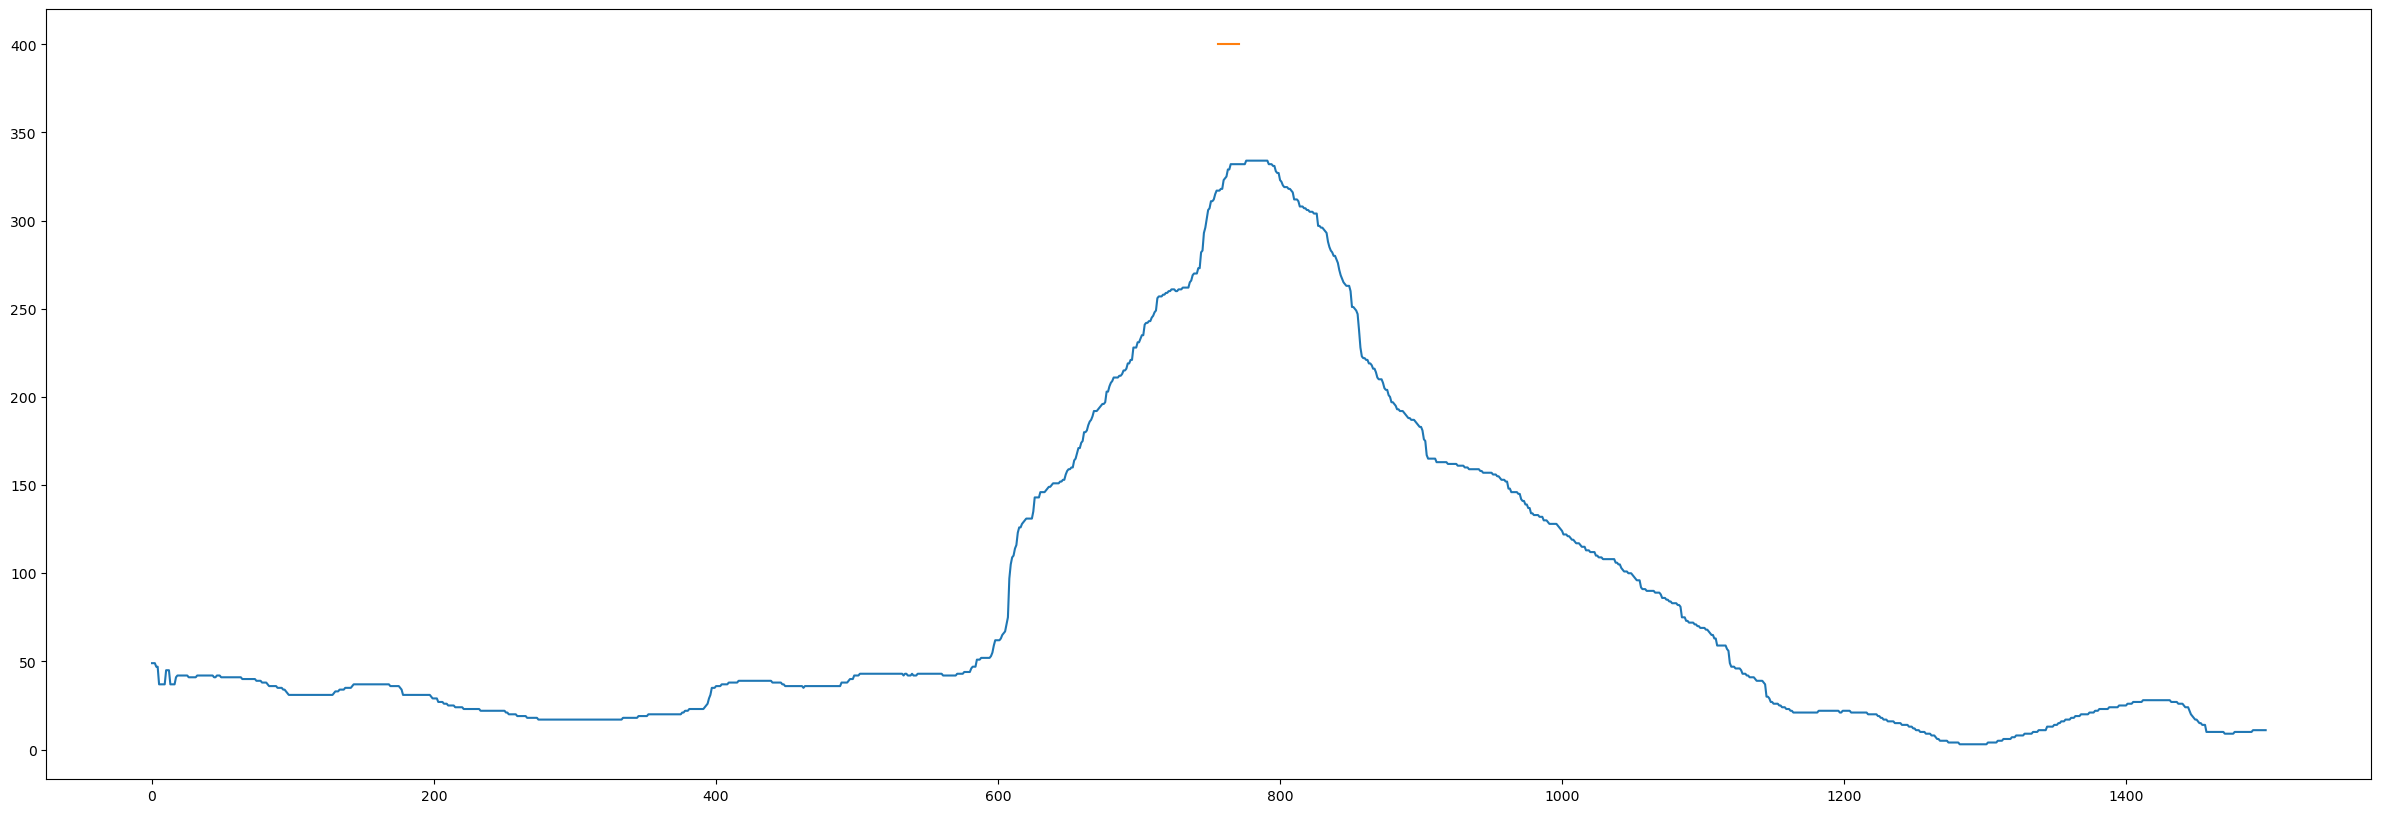

In [19]:
plt.figure(figsize=(30,10))
plt.plot(x,median_filter(np.abs(Positions-500),40))
peak = np.where(Matti==np.max(Matti))[0]
plt.plot(peak, np.ones(len(peak))*400)

In [20]:
new_center = np.median(np.where(Matti==np.max(Matti))[0])
print(new_center)
print(int(new_center))
new_center = int(new_center)

763.5
763


(-73.95, 1552.95, -13.55, 350.55)

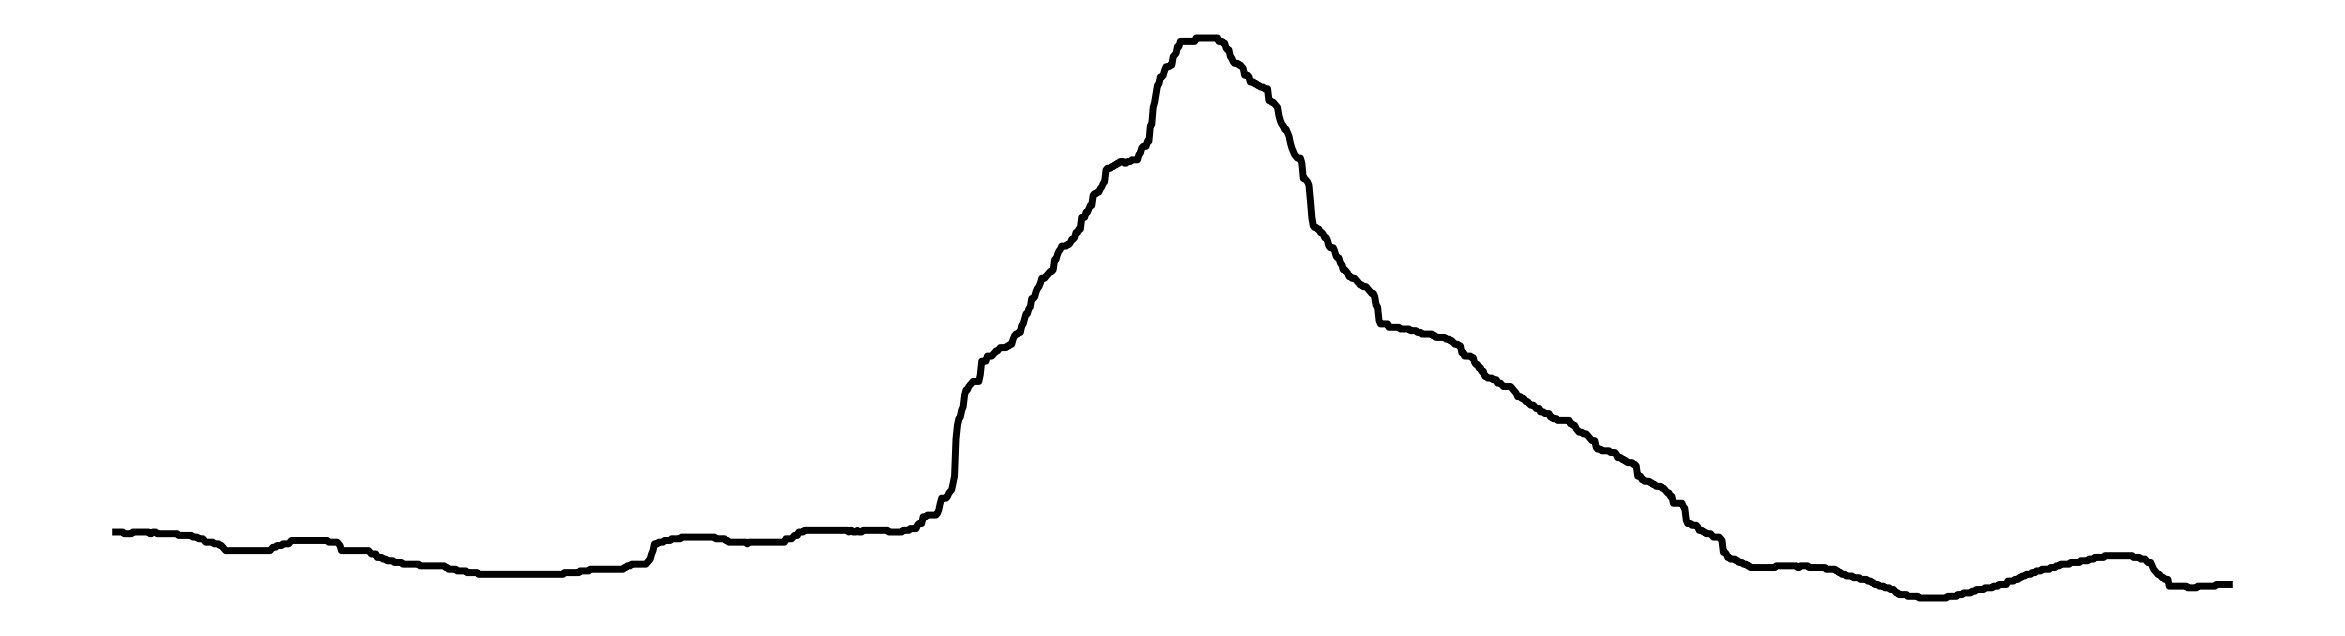

In [21]:
plt.figure(figsize=(30,8))
plt.plot(Matti,lw=5,c='black')
plt.axis('off')

In [23]:
new_x = np.arange( -new_center , np.max(x)-new_center-19 ,1 )
print(new_x)
print(len(new_x))

[-763 -762 -761 ...  714  715  716]
1480


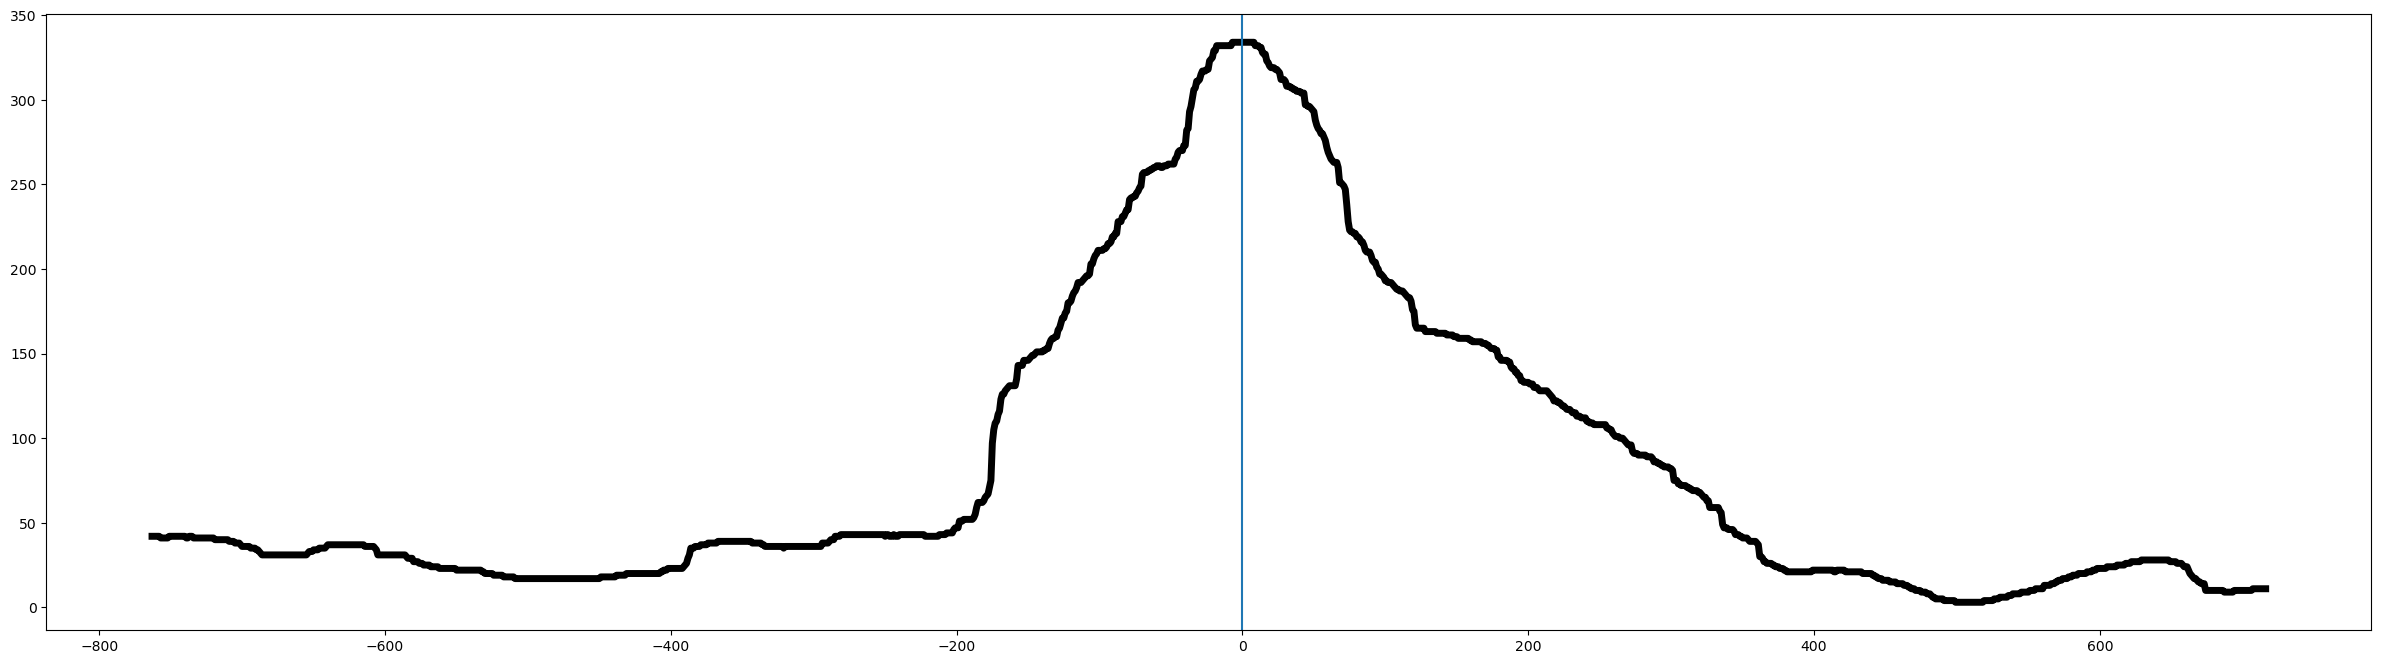

In [24]:
fig = plt.figure(figsize=(30,8))
plt.plot(new_x,Matti,lw=5,c='black')
plt.axvline(0)

## 3. Model functions

In [25]:
def Gauss(x,a,mu,sigma):
    return a*np.exp(-0.5*((x-mu)/sigma)**2)

def Moffat(x,a,x0,gamma,beta):
    return a*( 1 + ((x-x0)/gamma)**2 )**(-beta)

def SkewedGauss(x,a1,a2,mu,sigma1,sigma2):
    
    func_left = Gauss(x,a1,mu,sigma1)
    func_right = Gauss(x,a2,mu,sigma2)
    
    mask_left = x < mu
    mask_right = x >= mu 
    
    outp = np.zeros(x.shape)
    outp[mask_left] = func_left[mask_left]
    outp[mask_right] = func_right[mask_right]
    
    return outp

def SkewedMoffat(x,a1,a2,x0,gamma1,gamma2,beta1,beta2):
    
    func_left = Moffat(x,a1,x0,gamma1, beta1)
    func_right = Moffat(x,a2,x0,gamma2,beta2)
    
    mask_left = x < x0
    mask_right = x >= x0 
    
    outp = np.zeros(x.shape)
    outp[mask_left] = func_left[mask_left]
    outp[mask_right] = func_right[mask_right]
    
    return outp

def Poly10D(x,a40,a39,a38,a37,a36,a35,a34,a33,a32,a31,a30,a29,a28,a27,a26,a25,a24,a23,a22,a21,a20,a19,a18,a17,a16,a15,a14,a13,a12,a11,a10,a9,a8,a7,a6,a5,a4,a3,a2,a1,a0):
    return a40*x**40 + a39*x**39 + a38*x**38 + a37*x**37 + a36*x**36 + a35*x**35 + a34*x**34 + a33*x**33 + a32*x**32 + a31*x**31 + a30*x**30 + a29*x**29 + a28*x**28 + a27*x**27 + a26*x**26 + a25*x**25 + a24*x**24 + a23*x**23 + a22*x**22 + a21*x**21 + a20*x**20 + a19*x**19 + a18*x**18 + a17*x**17 + a16*x**16 + a15*x**15 + a14*x**14 + a13*x**13 + a12*x**12 + a11*x**11 + a10*x**10 + a9*x**9 + a8*x**8 + a7*x**7 + a6*x**6 + a5*x**5 + a4*x**4 + a3*x**3 + a2*x**2 + a1*x + a0 

def Poly50D(x,a50,a49,a48,a47,a46,a45,a44,a43,a42,a41,a40,a39,a38,a37,a36,a35,a34,a33,a32,a31,a30,a29,a28,a27,a26,a25,a24,a23,a22,a21,a20,a19,a18,a17,a16,a15,a14,a13,a12,a11,a10,a9,a8,a7,a6,a5,a4,a3,a2,a1,a0):
    return a50*x**50 + a49*x**49 + a48*x**48 + a47*x**47 + a46*x**46 + a45*x**45 + a44*x**44 + a43*x**43 + a42*x**42 + a41*x**41 + a40*x**40 + a39*x**39 + a38*x**38 + a37*x**37 + a36*x**36 + a35*x**35 + a34*x**34 + a33*x**33 + a32*x**32 + a31*x**31 + a30*x**30 + a29*x**29 + a28*x**28 + a27*x**27 + a26*x**26 + a25*x**25 + a24*x**24 + a23*x**23 + a22*x**22 + a21*x**21 + a20*x**20 + a19*x**19 + a18*x**18 + a17*x**17 + a16*x**16 + a15*x**15 + a14*x**14 + a13*x**13 + a12*x**12 + a11*x**11 + a10*x**10 + a9*x**9 + a8*x**8 + a7*x**7 + a6*x**6 + a5*x**5 + a4*x**4 + a3*x**3 + a2*x**2 + a1*x + a0 







## 4. Fits with lmfit

[[Model]]
    Model(Gauss)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 1480
    # variables        = 3
    chi-square         = 986652.157
    reduced chi-square = 668.010939
    Akaike info crit   = 9629.36769
    Bayesian info crit = 9645.26708
    R-squared          = 0.91950508
[[Variables]]
    a:      288.462162 +/- 1.97325419 (0.68%) (init = 400)
    mu:     16.9702271 +/- 1.14683723 (6.76%) (init = 0)
    sigma:  145.186097 +/- 1.14683722 (0.79%) (init = 175)
[[Correlations]] (unreported correlations are < 0.100)
    C(a, sigma) = -0.577
[[Model]]
    Model(SkewedGauss)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 109
    # data points      = 1480
    # variables        = 5
    chi-square         = 754373.454
    reduced chi-square = 511.439630
    Akaike info crit   = 9236.09127
    Bayesian info crit = 9262.59026
    R-squared          = 0.93845528
[[Variables]]
    a1:      248.25519

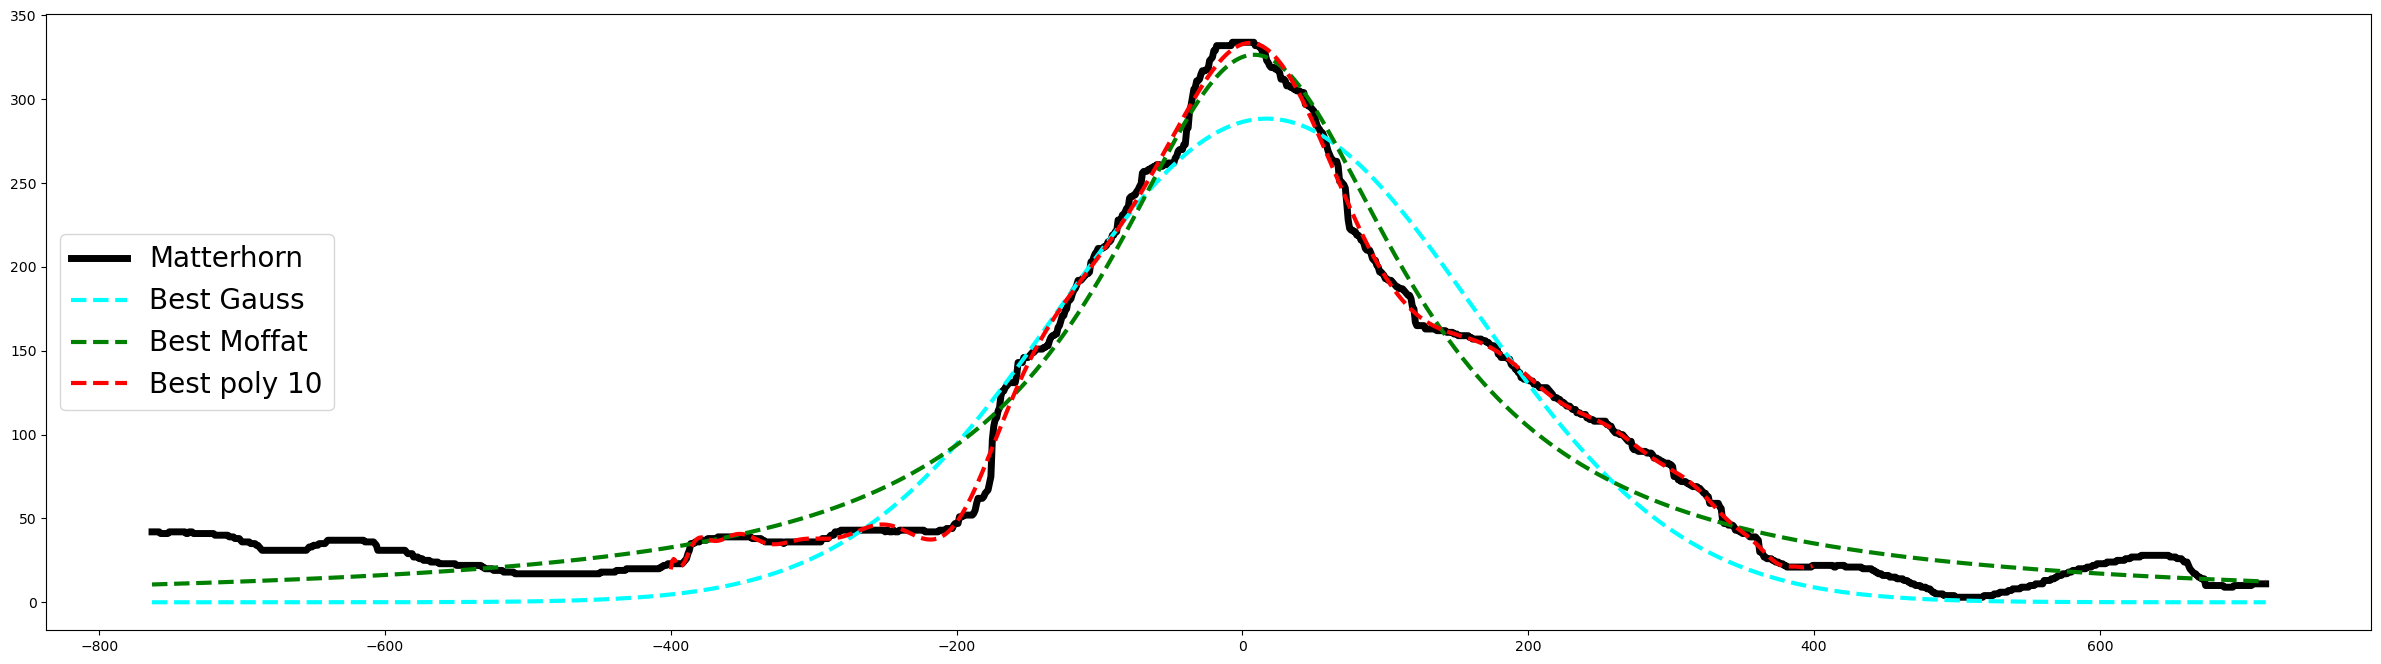

In [27]:
g_mod = Model(Gauss)
m_mod = Model(Moffat)
s_mod = Model(SkewedGauss)
sm_mod = Model(SkewedMoffat)
p_mod = Model(Poly10D)
p_mod5 = Model(Poly50D)


g_res = g_mod.fit(Matti, x=new_x, a=400., mu=0., sigma=175.)
m_res = m_mod.fit(Matti, x=new_x, a=400., x0=0., gamma=1., beta=1.)
s_res = s_mod.fit(Matti, x=new_x, a1=400., a2=400., mu=0., sigma1=150., sigma2=170.)
sm_res = sm_mod.fit(Matti, x=new_x, a1=400., a2=400., x0=0., gamma1=124., gamma2=124.,beta1=1., beta2=1.)
p_res = p_mod.fit(Matti, x=new_x,a40=0.,a39=0.,a38=0.,a37=0.,a36=0.,a35=0.,a34=0.,a33=0.,a32=0.,a31=0.,a30=0.,a29=0.,a28=0.,a27=0.,a26=0.,a25=0.,a24=0.,a23=0,a22=0.,a21=0.,a20=0.,a19=0.,a18=0.,a17=0.,a16=0.,a15=0.,a14=0,a13=0.,a12=0.,a11=0.,a10=0.,a9=0.,a8=0.,a7=0.,a6=0.,a5=0.,a4=0.,a3=0.,a2=0.,a1=0.,a0=0.)
p_res5 = p_mod5.fit(Matti, x=new_x,a50=0.,a49=0.,a48=0.,a47=0.,a46=0.,a45=0.,a44=0.,a43=0.,a42=0.,a41=0.,a40=0.,a39=0.,a38=0.,a37=0.,a36=0.,a35=0.,a34=0.,a33=0.,a32=0.,a31=0.,a30=0.,a29=0.,a28=0.,a27=0.,a26=0.,a25=0.,a24=0.,a23=0,a22=0.,a21=0.,a20=0.,a19=0.,a18=0.,a17=0.,a16=0.,a15=0.,a14=0,a13=0.,a12=0.,a11=0.,a10=0.,a9=0.,a8=0.,a7=0.,a6=0.,a5=0.,a4=0.,a3=0.,a2=0.,a1=0.,a0=0.)


p_res2 = p_mod.fit(Matti[363:1163], x=new_x[363:1163],a40=0.,a39=0.,a38=0.,a37=0.,a36=0.,a35=0.,a34=0.,a33=0.,a32=0.,a31=0.,a30=0.,a29=0.,a28=0.,a27=0.,a26=0.,a25=0.,a24=0.,a23=0,a22=0.,a21=0.,a20=0.,a19=0.,a18=0.,a17=0.,a16=0.,a15=0.,a14=0,a13=0.,a12=0.,a11=0.,a10=0.,a9=0.,a8=0.,a7=0.,a6=0.,a5=0.,a4=0.,a3=0.,a2=0.,a1=0.,a0=0.)


print(g_res.fit_report())
#print(m_res.fit_report())
print(s_res.fit_report())
#print(sm_res.fit_report())
#print(p_res.fit_report())
                   
plt.figure(figsize=(30,8))
plt.plot(new_x, Matti, lw=5,c='black', label = 'Matterhorn')
plt.plot(new_x, g_res.best_fit,lw=3,ls='dashed',c='cyan',label='Best Gauss')
plt.plot(new_x, m_res.best_fit,lw=3,ls='dashed',c='green',label='Best Moffat')
#plt.plot(new_x, s_res.best_fit,lw=3,ls='dashed',c='blue',label='Best Skewed')
#plt.plot(new_x, sm_res.best_fit,lw=3,ls='dashed',c='gray',label='Best Skewed M')
#plt.plot(new_x, p_res.best_fit,lw=3,ls='dashed',c='red',label='Best poly 10')
plt.plot(new_x[363:1163], p_res2.best_fit,lw=3,ls='dashed',c='red',label='Best poly 10')
#plt.plot(new_x, p_res5.best_fit,lw=3,ls='dashed',c='red',label='Best poly 50')

plt.legend(loc=6,fontsize=20)

## 5. Downsampled profile and plots

In [29]:
MattiShort = []
new_xShort = []
for i in range(int(len(Matti)/2)):
    MattiShort.append(Matti[2*i])
    new_xShort.append(new_x[2*i])
MattiShort = np.array(MattiShort)
new_xShort = np.array(new_xShort)

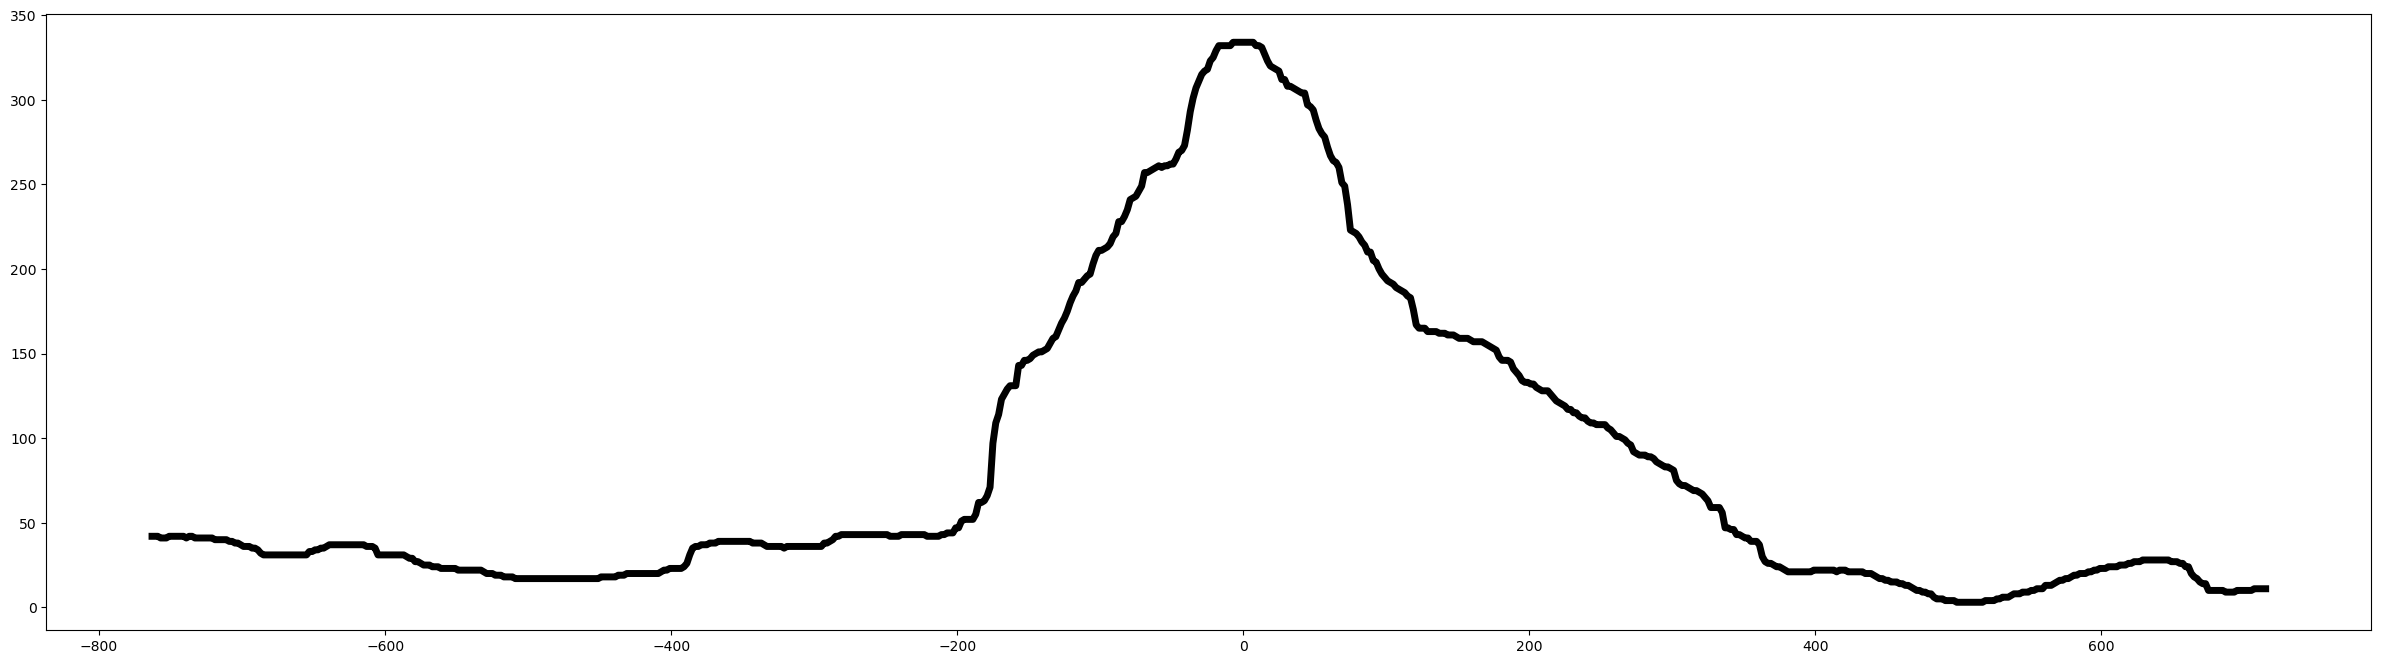

In [31]:
plt.figure(figsize=(30,8))
plt.plot(new_xShort, MattiShort, lw=5,c='black', label = 'Matterhorn')

In [32]:
MattiShort2x = []
new_xShort2x = []
for i in range(int(len(MattiShort)/2)):
    MattiShort2x.append(MattiShort[2*i])
    new_xShort2x.append(new_xShort[2*i])
MattiShort2x = np.array(MattiShort2x)
new_xShort2x = np.array(new_xShort2x)

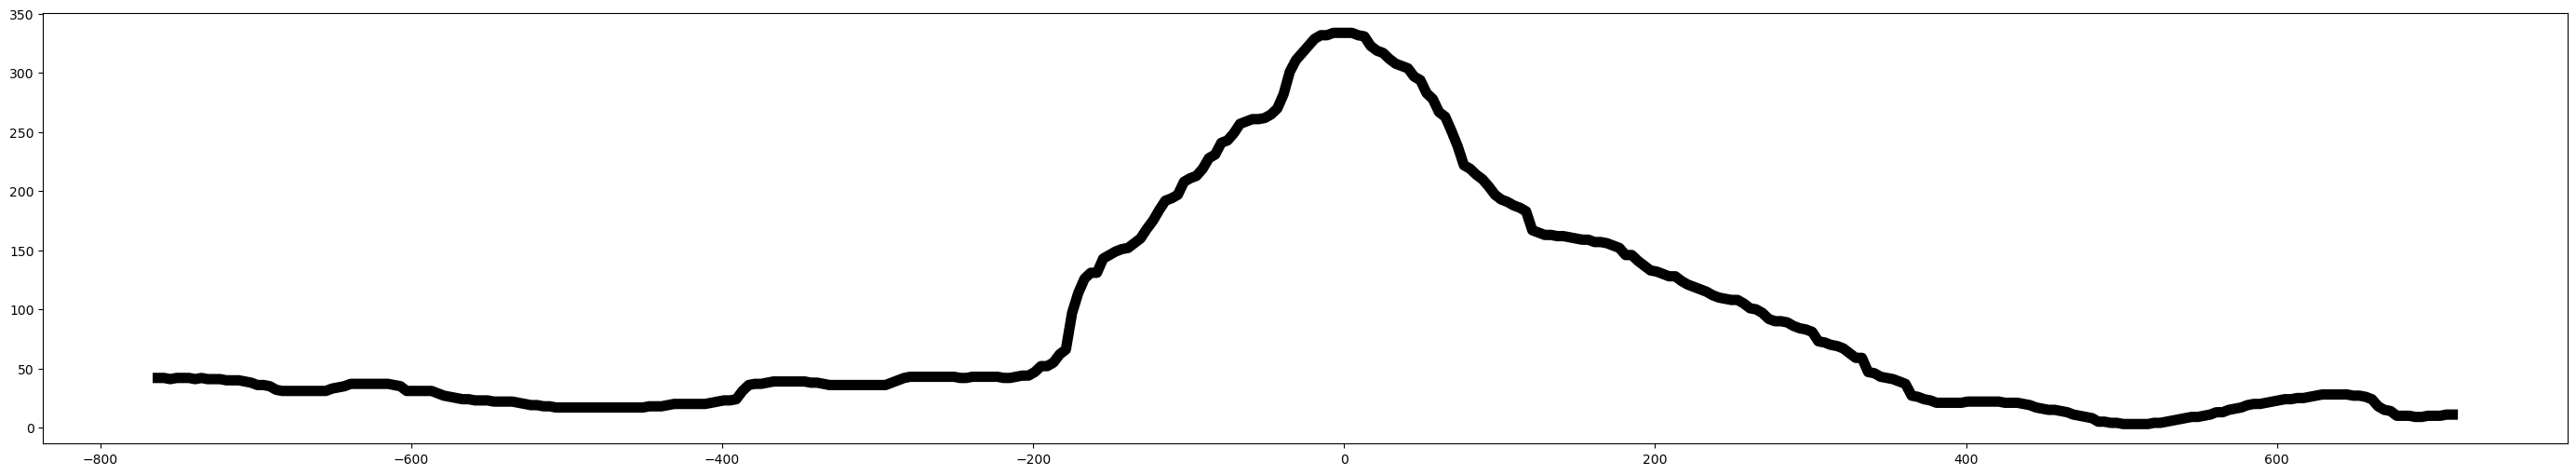

In [33]:
fig = plt.figure(figsize=(35,6))
plt.plot(new_xShort2x, MattiShort2x, lw=8,c='black', label = 'Matterhorn')
#plt.axis('off')
#fig.savefig('MatterhornNew.png',format='png',dpi=200)

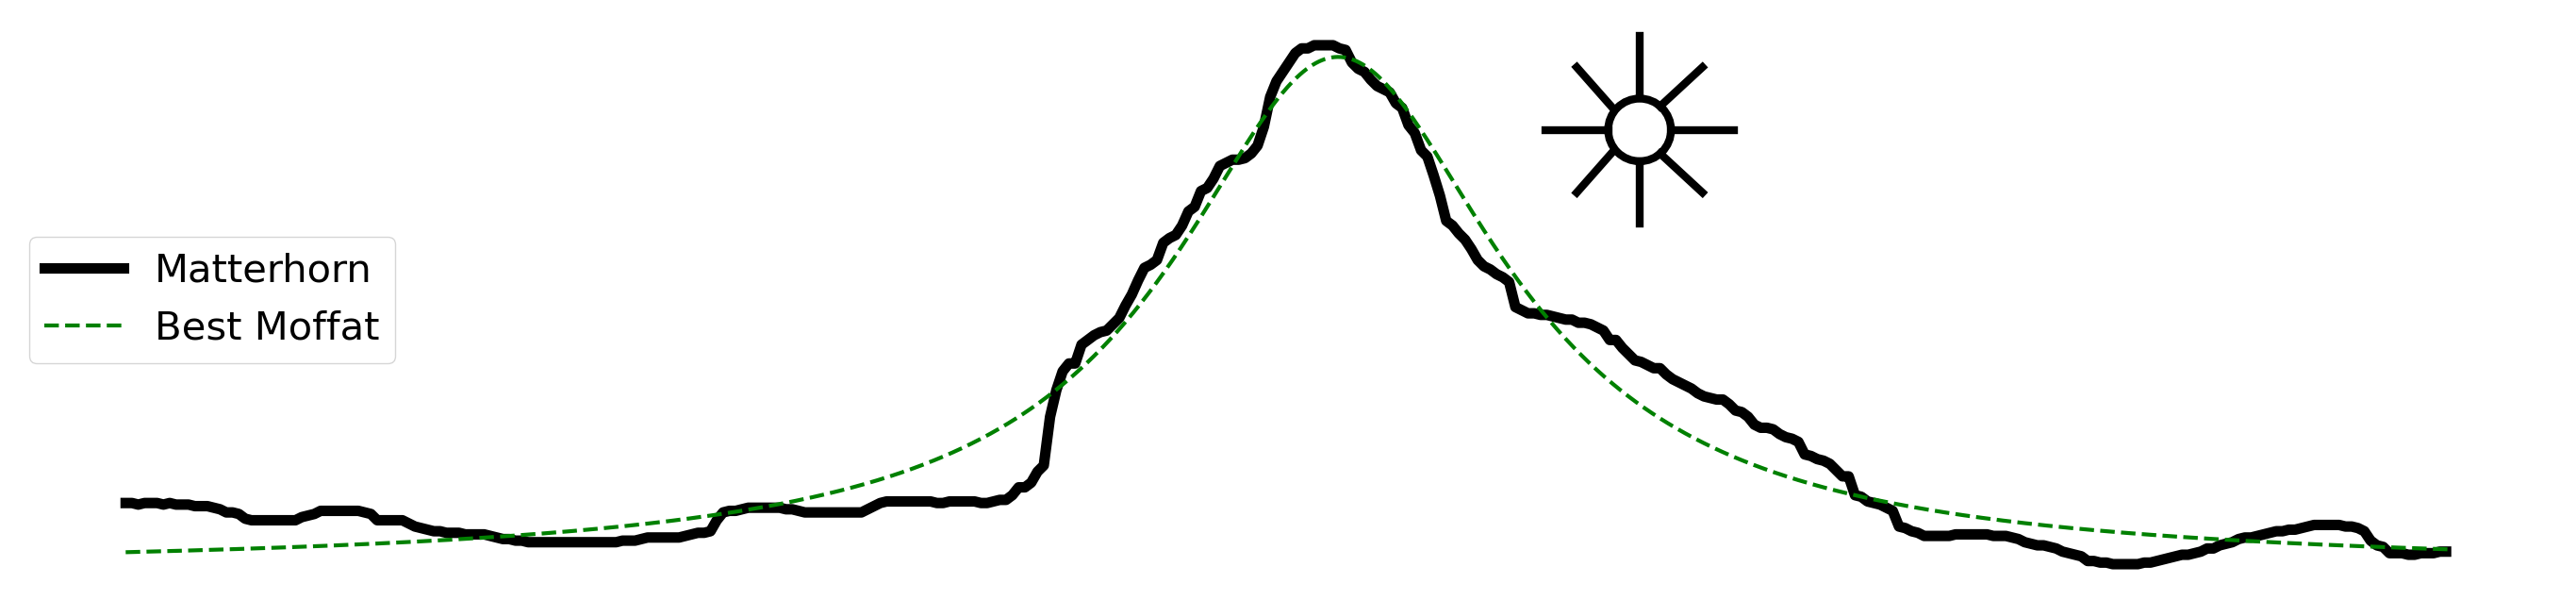

In [35]:
fig, ax = plt.subplots(1,figsize=(35,8))
circle = plt.Circle((200, 280), 20, color='black',fill=False,lw=6)
plt.plot(new_xShort2x, MattiShort2x, lw=8,c='black', label = 'Matterhorn')

plt.plot([140,180],[280,280],lw=6,c='black') # gauche
plt.plot([220,260],[280,280],lw=6,c='black') # droite
plt.plot([200,200],[300,340],lw=6,c='black') # haut
plt.plot([200,200],[220,260],lw=6,c='black') # bas

plt.plot([213,240],[265,240],lw=6,c='black') # bas droite
plt.plot([160,182],[240,265],lw=6,c='black') # bas gauche
plt.plot([160,182],[320,295],lw=6,c='black') # haut gauche 
plt.plot([213,240],[295,320],lw=6,c='black') # haut droite 

plt.plot(new_x, m_res.best_fit,lw=3,ls='dashed',c='green',label='Best Moffat')


plt.axis('off')

#plt.scatter(145,225,color='red')
#plt.scatter(180,265,color='red')
ax.add_artist(circle)
plt.legend(loc=6,fontsize=30)
#fig.savefig('MatterhornSun.png',format='png',dpi=200)

Fitting with astropy models that has a polynomial function of degree of choice instead of lmfit for which I manually defined the function

(-836.95, 789.95, -13.850000000000001, 356.85)

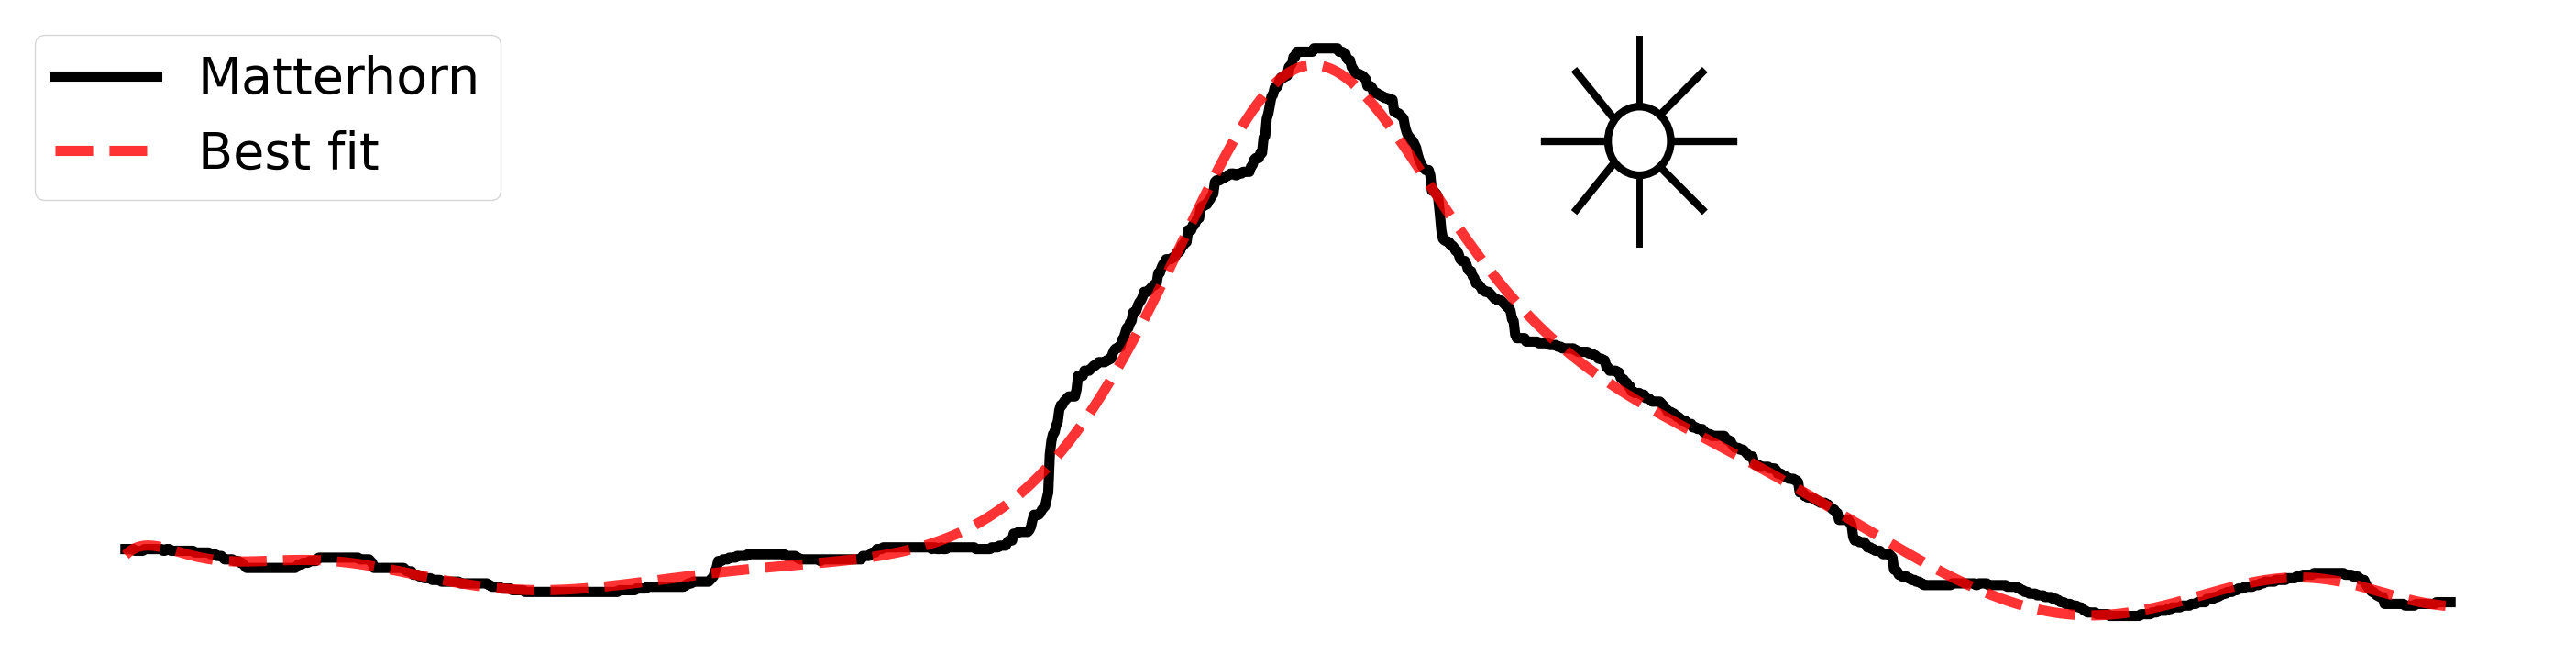

In [36]:
from astropy.modeling import models, fitting

model_init = models.Moffat1D(amplitude=350, x_0 = 0) + models.Polynomial1D(degree=20)#, domain=(-200,200))#, window(-800,800)
fit_model = fitting.LevMarLSQFitter()
model = fit_model(model_init, new_x, Matti, maxiter=1000)


fig, ax = plt.subplots(1,figsize=(36,9))
plt.plot(new_x, Matti, lw=8,c='black', label = 'Matterhorn')
plt.plot(new_x, model(new_x), label="Best fit", lw=8, color="red", alpha=0.8,linestyle="dashed")

###
circle = plt.Circle((200, 280), 20, color='black',fill=False,lw=6)
ax.add_artist(circle)

plt.plot([140,180],[280,280],lw=6,c='black') # gauche
plt.plot([220,260],[280,280],lw=6,c='black') # droite
plt.plot([200,200],[300,340],lw=5,c='black') # haut
plt.plot([200,200],[220,260],lw=5,c='black') # bas

plt.plot([213,240],[265,240],lw=6,c='black') # bas droite
plt.plot([160,182],[240,265],lw=6,c='black') # bas gauche
plt.plot([160,182],[320,295],lw=6,c='black') # haut gauche 
plt.plot([213,240],[295,320],lw=6,c='black') # haut droite 
###

plt.legend(loc=2,fontsize=40)
plt.axis('off')

#fig.savefig('MatterhornFitTaty.png',format='png',dpi=200)

## Negative plot of it

/var/folders/dc/3z26p4hj1l96tsyszfgd7j1r0000gp/T/ipykernel_54452/1858217852.py:28: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "doi" which is no longer supported as of 3.3 and will become an error in 3.6
  fig.savefig('MatterhornFitWhiteWide.png',transparent=True,format='png',doi=280)


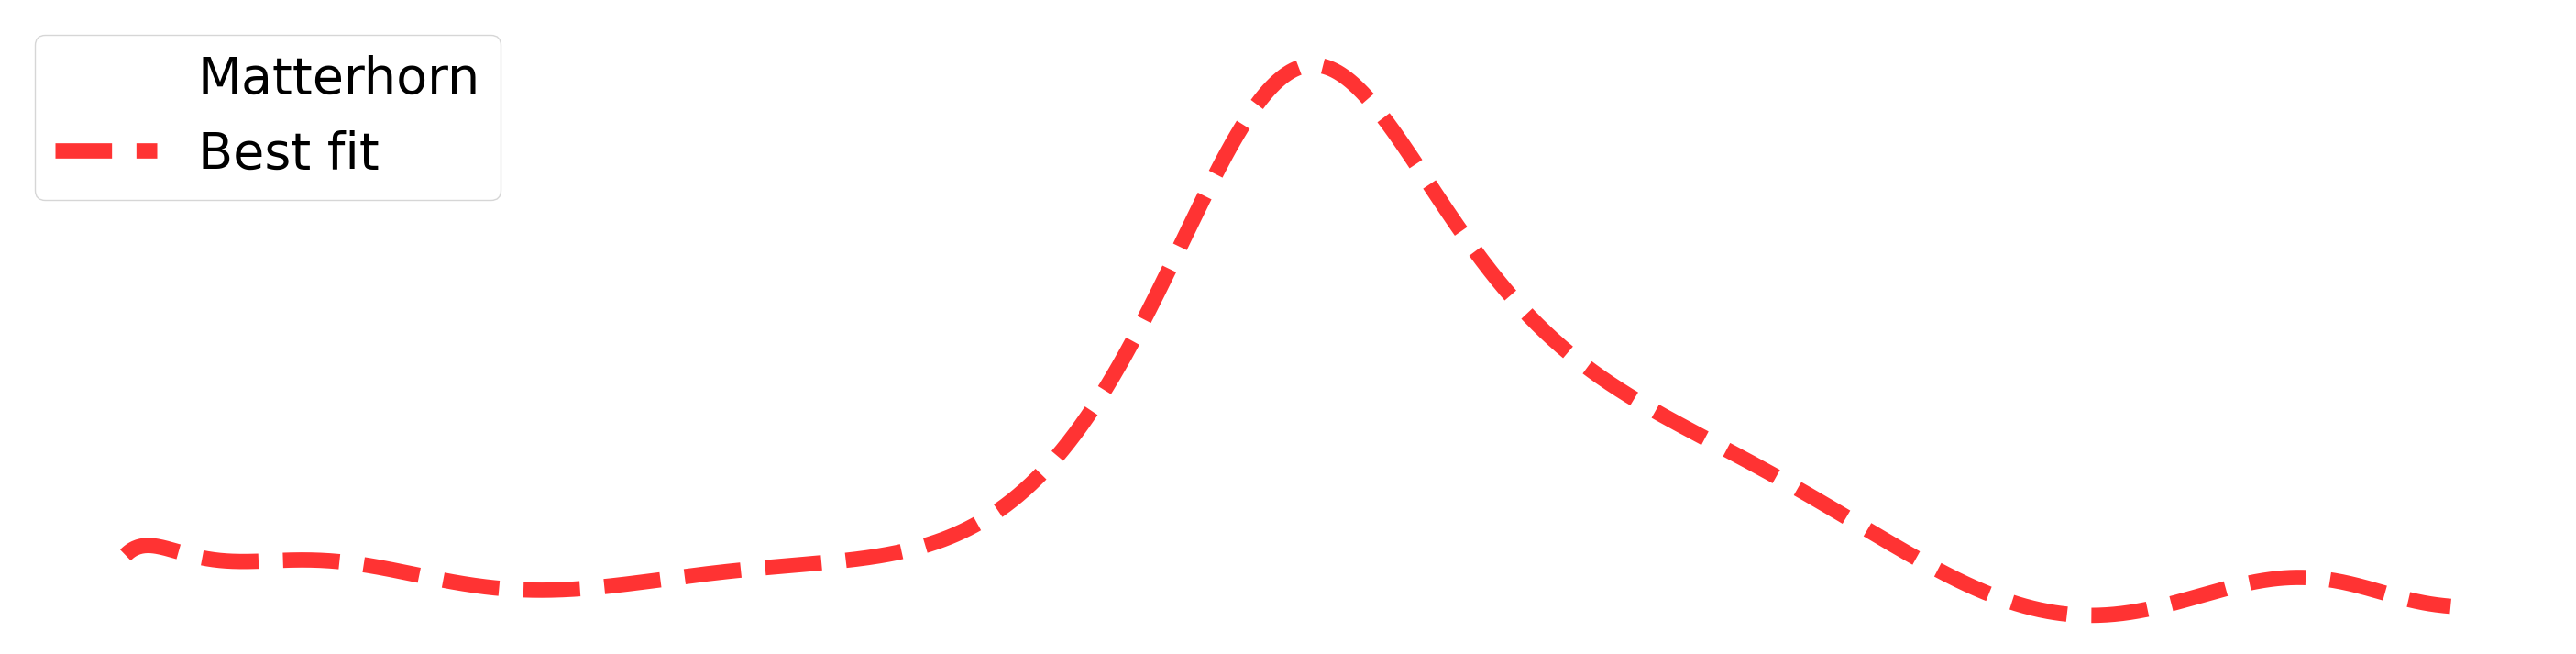

In [40]:
model_init = models.Moffat1D(amplitude=350, x_0 = 0) + models.Polynomial1D(degree=20)#, domain=(-200,200))#, window(-800,800)
fit_model = fitting.LevMarLSQFitter()
model = fit_model(model_init, new_x, Matti, maxiter=1000)


fig, ax = plt.subplots(1,figsize=(36,9))
plt.plot(new_x, Matti, lw=8,c='white', label = 'Matterhorn')
plt.plot(new_x, model(new_x), label="Best fit", lw=12, color="red", alpha=0.8,linestyle="dashed")

###
circle = plt.Circle((200, 280), 20, color='white',fill=False,lw=8)
ax.add_artist(circle)

plt.plot([140,180],[280,280],lw=10,c='white') # gauche
plt.plot([220,260],[280,280],lw=10,c='white') # droite
plt.plot([200,200],[300,340],lw=10,c='white') # haut
plt.plot([200,200],[220,260],lw=10,c='white') # bas

plt.plot([213,240],[265,240],lw=10,c='white') # bas droite
plt.plot([160,182],[240,265],lw=10,c='white') # bas gauche
plt.plot([160,182],[320,295],lw=10,c='white') # haut gauche 
plt.plot([213,240],[295,320],lw=10,c='white') # haut droite 
###

plt.legend(loc=2,fontsize=40)
plt.axis('off')

fig.savefig('MatterhornFitWhiteWide.png',transparent=True,format='png',dpi=280)